# Install Pustaka


In [1]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import warnings
warnings.filterwarnings('ignore')

# Buat folder penyimpanan hasil
os.makedirs('output', exist_ok=True)

print("Semua pustaka berhasil diimpor!")

Semua pustaka berhasil diimpor!


# Dataset & Cek Kualitas

In [2]:
# Membaca file excel yang sudah diunggah
df_mentah = pd.read_excel('case6_traffic_accident.xlsx')

print("Ukuran Data Mentah:", df_mentah.shape)
print("\n--- 5 Baris Pertama Data ---")
df_mentah.head()

Ukuran Data Mentah: (3000, 17)

--- 5 Baris Pertama Data ---


,accident_id,tanggal,jam,hari,kota,tipe_jalan,kondisi_cuaca,kondisi_pencahayaan,kondisi_permukaan_jalan,jenis_kendaraan,jumlah_kendaraan_terlibat,jumlah_korban,batas_kecepatan_kmh,usia_pengemudi,jenis_kelamin_pengemudi,alkohol_terdeteksi,tingkat_keparahan
0,ACC000001,2020-01-16,7.0,Kamis,Bandung,Jalan Nasional,Cerah,Siang,Kering,Mobil,5.0,3.0,50.0,23.0,Laki-laki,Tidak,Sedang
1,ACC000002,2022-12-25,NaN,Sabtu,Surabaya,Jalan Kota,berkabut,Siang,Kering,Sepeda Motor,3.0,2.0,50.0,59.0,Laki-laki,Ya,Sedang
2,ACC000003,2024-07-20,19.0,Rabu,Jakarta,Jalan Kota,Hujan Lebat,Malam,Berlubang,NaN,2.0,1.0,100.0,45.0,Perempuan,Tidak,Sedang
3,ACC000004,2022-01-20,0.0,Minggu,Bali,Jalan Kota,Cerah,Malam,Kering,Bus,2.0,7.0,40.0,23.0,Perempuan,Ya,Berat
4,ACC000005,2024-05-22,7.0,Rabu,Bandung,Jalan Tol,Cerah,Siang,Kering,Truk,2.0,0.0,80.0,23.0,Laki-laki,Tidak,Ringan


# clean data

In [6]:
df_bersih = df_mentah.copy()

# 1. Hapus duplikat berdasarkan ID
df_bersih = df_bersih.drop_duplicates(subset=['accident_id']).reset_index(drop=True)

# 2. Perbaiki string typo pada kondisi cuaca & kembalikan 'nan' string menjadi NaN sesungguhnya
df_bersih['kondisi_cuaca'] = df_bersih['kondisi_cuaca'].astype(str).str.lower()
df_bersih['kondisi_cuaca'] = df_bersih['kondisi_cuaca'].str.replace('@', 'a').str.title()
df_bersih['kondisi_cuaca'] = df_bersih['kondisi_cuaca'].replace({'Nan': np.nan, 'nan': np.nan})

# 3. Isi nilai kosong pada kolom numerik (menggunakan median)
num_cols = ['jam', 'jumlah_kendaraan_terlibat', 'jumlah_korban', 'batas_kecepatan_kmh', 'usia_pengemudi']
for col in num_cols:
    df_bersih[col] = df_bersih[col].fillna(df_bersih[col].median())

# 4. Isi nilai kosong pada kolom kategorikal (menggunakan modus/nilai terbanyak)
cat_cols = ['hari', 'kota', 'tipe_jalan', 'kondisi_cuaca', 'kondisi_pencahayaan',
            'kondisi_permukaan_jalan', 'jenis_kendaraan', 'jenis_kelamin_pengemudi', 'alkohol_terdeteksi']
for col in cat_cols:
    df_bersih[col] = df_bersih[col].fillna(df_bersih[col].mode()[0])

# 5. Isi nilai kosong pada kolom tanggal (menggunakan ffill / mode)
if 'tanggal' in df_bersih.columns:
    df_bersih['tanggal'] = pd.to_datetime(df_bersih['tanggal']).fillna(method='ffill')

print("Pembersihan data selesai! Jumlah data kosong:", df_bersih.isnull().sum().sum())

Pembersihan data selesai! Jumlah data kosong: 0


# visualisasi data

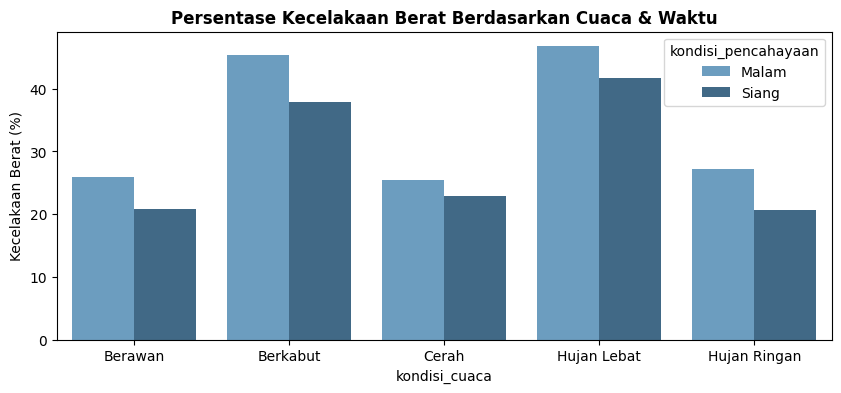

In [7]:
# Hitung persentase kecelakaan berat per cuaca & pencahayaan
analisis_cuaca = df_bersih.groupby(['kondisi_cuaca', 'kondisi_pencahayaan']).agg(
    persen_berat=('tingkat_keparahan', lambda s: (s == 'Berat').mean() * 100)
).reset_index()

# Tampilkan grafik
plt.figure(figsize=(10, 4))
sns.barplot(data=analisis_cuaca, x='kondisi_cuaca', y='persen_berat', hue='kondisi_pencahayaan', palette='Blues_d')
plt.title('Persentase Kecelakaan Berat Berdasarkan Cuaca & Waktu', fontweight='bold')
plt.ylabel('Kecelakaan Berat (%)')
plt.show()

# save dan unduh data

In [8]:
from google.colab import files

# Simpan data yang sudah bersih ke dalam folder output
df_bersih.to_csv('output/data_bersih.csv', index=False)

# Unduh langsung file CSV hasil pembersihan ke komputer Anda
files.download('output/data_bersih.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import pandas as pd
from google.colab import files

# 1. Fungsi audit kualitas data
def cek_kualitas(d, kolom_num, kolom_grup, kunci):
    g  = d.groupby(kolom_grup, observed=True)[kolom_num]
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    outlier = (d[kolom_num] < q1 - 1.5 * iqr) | (d[kolom_num] > q3 + 1.5 * iqr)
    return pd.Series({
        'n_baris':    len(d),
        'n_duplikat': d.duplicated(subset=kunci).sum(),
        'n_missing':  d.isnull().sum().sum(),
        'n_outlier':  outlier.sum(),
    })

# 2. Buat tabel perbandingan sebelum vs sesudah
laporan_kualitas = pd.DataFrame({
    'sebelum': cek_kualitas(df_mentah, 'jumlah_korban', 'tipe_jalan', 'accident_id'),
    'sesudah': cek_kualitas(df_bersih, 'jumlah_korban', 'tipe_jalan', 'accident_id'),
})

# 3. Simpan file laporan_kualitas.csv
laporan_kualitas.to_csv('laporan_kualitas.csv')
print("File laporan_kualitas.csv berhasil dibuat!")

# 4. Baru kemudian unduh semua file output
files.download('output/data_bersih.csv')
files.download('output/kamus_data.csv')
files.download('laporan_kualitas.csv')

File laporan_kualitas.csv berhasil dibuat!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
from google.colab import files

# 1. Simpan data bersih (menggunakan data yang sudah 0 missing value)
df_bersih.to_csv('output/data_bersih.csv', index=False)

# 2. Buat & Simpan Kamus Data
kamus_data = pd.DataFrame({
    'nama_kolom': df_bersih.columns,
    'tipe_data': df_bersih.dtypes.values,
    'n_missing': df_bersih.isnull().sum().values,
    'n_unik': df_bersih.nunique().values
})
kamus_data.to_csv('output/kamus_data.csv', index=False)

# 3. Download file
files.download('output/data_bersih.csv')
files.download('output/kamus_data.csv')
files.download('laporan_kualitas.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>